# Сақ бол: scam early warning for Kazakhstan, in Kazakh, Russian and the mix people actually type
**Track:** Finance. **This project is a prototype and is not financial advice.**

A model that reads a message or a call transcript and says whether it looks like a scam, which phrase made it think so, and what to do, in Kazakh or Russian.
Every number below comes from real Kazakhstan scam texts collected word for word from public pages, which the model never saw in training.

Run all cells top to bottom. Training ran on Kaggle T4 GPUs (scripts in `pipeline/`); this notebook loads the saved results and the trained model.

In [1]:
# Setup: works on Colab and locally
import os, sys, json, subprocess
if not os.path.exists("pipeline"):
    if not os.path.exists("saq-bol"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/itsaibarr/saq-bol"], check=True)
    os.chdir("saq-bol")
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=False)
sys.path.insert(0, "pipeline/src")
import pandas as pd, numpy as np
pd.set_option("display.max_colwidth", 120)
FINAL_RUN, MIX, HF_MODEL = "runs/ens_v7_e5x4_logit_z", "data/processed/mix_v7", "itsaibarr/saq-bol-v2"
REPORT, PREDS = "final_report_testB.json", "preds_final_testB.jsonl"  # v2 was scored on fresh test set B
print("ready")

ready


## 1. The real test set
Hand-collected from banks, regulators, police and news outlets in Kazakhstan (URLs and dates in `data/processed/real_all.jsonl`). Each item has a **unit**:
- `message` and `call_phrase` (5+ words): the **headline** set;
- `fragment` (4 words or fewer) and `description` (third-person scheme descriptions): reported separately or excluded;
- legit `notification` (real bank SMS and push texts) and `advice_text` (official anti-fraud advice that quotes scams).

Split into real-dev (model selection) and real-test A (version 1, scored once), grouped so translations and near-duplicates never straddle the split. After version 1 was frozen, test A moved into training and a fresh test set B (195 texts from pages never used before, `data/processed/testB.jsonl`) was collected and scored once for both versions.

In [2]:
tb = pd.read_json("data/processed/testB.jsonl", lines=True); print(len(tb), "test-B items"); display(pd.crosstab([tb.label, tb.unit], tb.language))
real = pd.read_json("data/processed/real_all.jsonl", lines=True)
print(len(real), "real items")
display(pd.crosstab([real.split, real.unit], real.language))
display(real[(real.split == "real_test") & real.headline].sample(6, random_state=1)[["language", "unit", "scheme", "text", "publisher", "published_date"]])

195 test-B items


language            kk  mixed  ru
label unit                       
0     advice_text   37      0   0
      notification   0      0   2
1     call_phrase   62      2  23
      fragment      24      0   3
      message       31      3   8

800 real items


language                en  kk  mixed  ru
split     unit                           
real_dev  advice_text    0  16      0   6
          call_phrase    0  28      1  26
          fragment       0  26      0  18
          message        0  37      0  22
          notification   0   9      2  34
real_test advice_text    0  57      0  29
          call_phrase    0  79      0  67
          description    0   8      0   9
          fragment       2  87      0  60
          message        0  67      0  41
          notification   0  13      2  54

,language,unit,scheme,text,publisher,published_date
191,kk,call_phrase,safe_account,"Шұғыл! Сіздің шотыңыздан/карточкаңыздан n сома есептен шығарылды, ақшаны дереу уақытша шотқа аудару қажет",Fingramota.kz (ARDFM financial literacy portal),2022-01-17
747,kk,message,fake_loan_telegram,Кредит ресімдеген адамдардың барлығына ай сайынғы 1 төлемін жауып береміз,Informburo.kz (citing Fingramota / ARDFM),2023-02-27
677,kk,message,fake_parental_control,"Бала телефонынан вирус табылды, қорғау орнату қажет",Fingramota.kz (ARDFM financial literacy portal),2025-11-26
728,kk,message,money_mule_recruitment,Аудару үшін карта қажет. Бірден төлейміз,Fingramota.kz (ARDFM financial literacy portal),2026-08-11
308,ru,call_phrase,fake_bank_security_loan_cancel,"Не надо сбрасывать, не надо сбрасывать",NUR.KZ (citing MVD / Karaganda police video),2024-04-29
705,kk,call_phrase,fake_delivery_code,Жеткізуді растау үшін SMS-тен кодты атаңыз,Fingramota.kz (ARDFM financial literacy portal),2026-08-31


## 2. Training data
No public labelled Kazakh scam data exists, so training combines: public Russian/English/multilingual scam corpora from Hugging Face, their Kazakh machine translations (NLLB-200 1.3B), synthetic Kazakhstan-specific messages and call phrases (generated with Claude under a fixed protocol, never shown the test set, two scheme types deliberately held out), ~27k real everyday Kazakh/Russian chat lines and ~5k rule-based bank/eGov notifications as negatives, and keyboard-Kazakh augmentation. Every training row was checked against the real set for leakage (char 5-gram Jaccard and LaBSE cosine).

In [3]:
stats = json.load(open(f"{MIX}/stats.json"))
print("training rows:", stats["n_train"], "| scam / legit:", stats["train_label"], "| rows dropped as near-copies of real items:", stats["leak_dropped"])
pd.Series(stats["train_source"]).sort_values(ascending=False).head(20)

training rows: 81156 | scam / legit: {'1': 17473, '0': 63683} | rows dropped as near-copies of real items: 146


tg_chat                                           26426
hf:DmitryKRX/anti_spam_ru                          6716
notif_gen                                          5144
hf:anmolshrivastav/scam_ham_india_14_languages     4323
hf:rasheq/scam-shield-sms                          3075
hf:VusalShahbazovAz/smishing-AZ-SC                 2879
notif_scam_twin                                    2202
real_real_test                                     2000
tg_chat+kbd_aug                                    1781
fraudlens_warning                                  1315
telegram_ham                                       1302
hf:Ridham115/indian-scam-sms-synthetic-audited     1236
notif_gen+kbd_aug                                  1058
hf_kk_nllb13b:rasheq/scam-shield-sms                908
synthetic_G5                                        888
synthetic_G6                                        880
hf:BothBosu/multi-agent-scam-conversation           821
hf:FredZhang7/all-scam-spam                     

## 3. Baselines and the model
Every model gets the same rule (SPEC.md A4): its threshold is the stricter of "flags at most 1% of everyday chat messages" and "flags at most 5% of real bank notifications", both measured on dev. Then we count how many real test scams it catches. (B1_keyword_rule_natural is the keyword rule at its own setting: at least one red flag.)

In [4]:
from evaluate import summary_line
rows = []
for name in ["B2_generic_spam_model", "B1_keyword_rule", "B1_keyword_rule_natural", "B3_tfidf_our_mix", "B5_offshelf_scam_model"]:
    rep = json.load(open(f"runs/{name}/report.json"))["test"]
    print(summary_line(name, rep))
final = json.load(open(f"{FINAL_RUN}/{REPORT}"))
print("--- Above: baselines on test set A (254 scams). Version 1 was frozen and scored once on test A:")
v1A = json.load(open("runs/ens_v6c_e5s2s3_logit_z/final_report.json"))
print(summary_line("v1 on test A", v1A["test"]))
print("--- Then test A moved into training; a fresh test set B was collected and both versions were scored on it once:")
v1B = json.load(open("runs/ens_v6c_e5s2s3_testB/final_report_testB.json"))
print(summary_line("v1 on test B", v1B["test"]))
print(summary_line("v2 (final) on test B", final["test"]))

B2_generic_spam_model          recall 0.047 [0.03,0.08] FN=242 | chatFPR 0.0025 notifFPR 0.072 | AP-vs-chat 0.256 | by lang {'kk': 0.0, 'ru': 0.11} | kk 0.0 -> kbd 0.0 | advice-flag 0.01
B1_keyword_rule                recall 0.035 [0.02,0.07] FN=245 | chatFPR 0.0000 notifFPR 0.029 | AP-vs-chat 0.419 | by lang {'kk': 0.01, 'ru': 0.06} | kk 0.01 -> kbd 0.01 | advice-flag 0.02
B1_keyword_rule_natural        recall 0.272 [0.22,0.33] FN=185 | chatFPR 0.0015 notifFPR 0.145 | AP-vs-chat 0.408 | by lang {'kk': 0.25, 'ru': 0.3} | kk 0.25 -> kbd 0.25 | advice-flag 0.14
B3_tfidf_our_mix               recall 0.437 [0.38,0.50] FN=143 | chatFPR 0.0020 notifFPR 0.159 | AP-vs-chat 0.838 | by lang {'kk': 0.45, 'ru': 0.42} | kk 0.45 -> kbd 0.49 | advice-flag 0.08
B5_offshelf_scam_model         recall 0.303 [0.25,0.36] FN=177 | chatFPR 0.0005 notifFPR 0.101 | AP-vs-chat 0.778 | by lang {'kk': 0.28, 'ru': 0.33} | kk 0.28 -> kbd 0.22 | advice-flag 0.01
--- Above: baselines on test set A (254 scams). Versio

## 4. Results by language, keyboard-Kazakh, and same-text pairs

In [5]:
t = final["test"]
def fmt(r): return "n<10" if r.get("rate") is None else f"{r['rate']:.1%} [{r['wilson95'][0]:.0%}, {r['wilson95'][1]:.0%}] (n={r['n']})"
print("Headline recall:", fmt(t["headline"]["recall"]), "| everyday-chat false alarms:", fmt(t["headline"]["chat_fpr"]), "| real bank-SMS false alarms:", fmt(t["headline"]["notification_fpr"]))
sc = t["headline_self_contained"]
print("Scams recognizable from text alone (blind annotation):", fmt(sc["recall"]), {k: fmt(v) for k, v in sc["by_language"].items()})
for l, r in t["recall_by_language"].items(): print(f"  recall {l}:", fmt(r))
print("Keyboard-Kazakh (same scams, letters folded):", t.get("kbd_paired"))
print("Kazakh/Russian translation pairs:", t.get("kk_ru_pairs"))
print("Secondary:", json.dumps({k: (v.get('rate'), v.get('n')) for k, v in t["secondary"].items()}, ensure_ascii=False, indent=1))

Headline recall: 82.2% [75%, 88%] (n=129) | everyday-chat false alarms: 0.1% [0%, 0%] (n=1978) | real bank-SMS false alarms: n<10
Scams recognizable from text alone (blind annotation): 88.4% [81%, 93%] (n=112) {'kk': '90.2% [82%, 95%] (n=82)', 'mixed': 'n<10', 'ru': '80.0% [61%, 91%] (n=25)'}
  recall kk: 87.1% [79%, 92%] (n=93)
  recall mixed: n<10
  recall ru: 64.5% [47%, 79%] (n=31)
Keyboard-Kazakh (same scams, letters folded): {'original_recall': {'n': 93, 'k': 81, 'rate': 0.8709677419354839, 'wilson95': [0.7878803375736373, 0.9246233798370623]}, 'folded_recall': {'n': 93, 'k': 71, 'rate': 0.7634408602150538, 'wilson95': [0.6677063852527946, 0.8382745155171224]}, 'test': {'n': 93, 'both': 67, 'only_first': 14, 'only_second': 4, 'neither': 8, 'mcnemar_p': 0.0308837890625}}
Kazakh/Russian translation pairs: None
Secondary: {
 "fragment_recall (<=4 words)": [
  0.8148148148148148,
  27
 ],
 "advice_text_flag_rate (anti-fraud advice that quotes scams; stress test)": [
  0.0810810810810

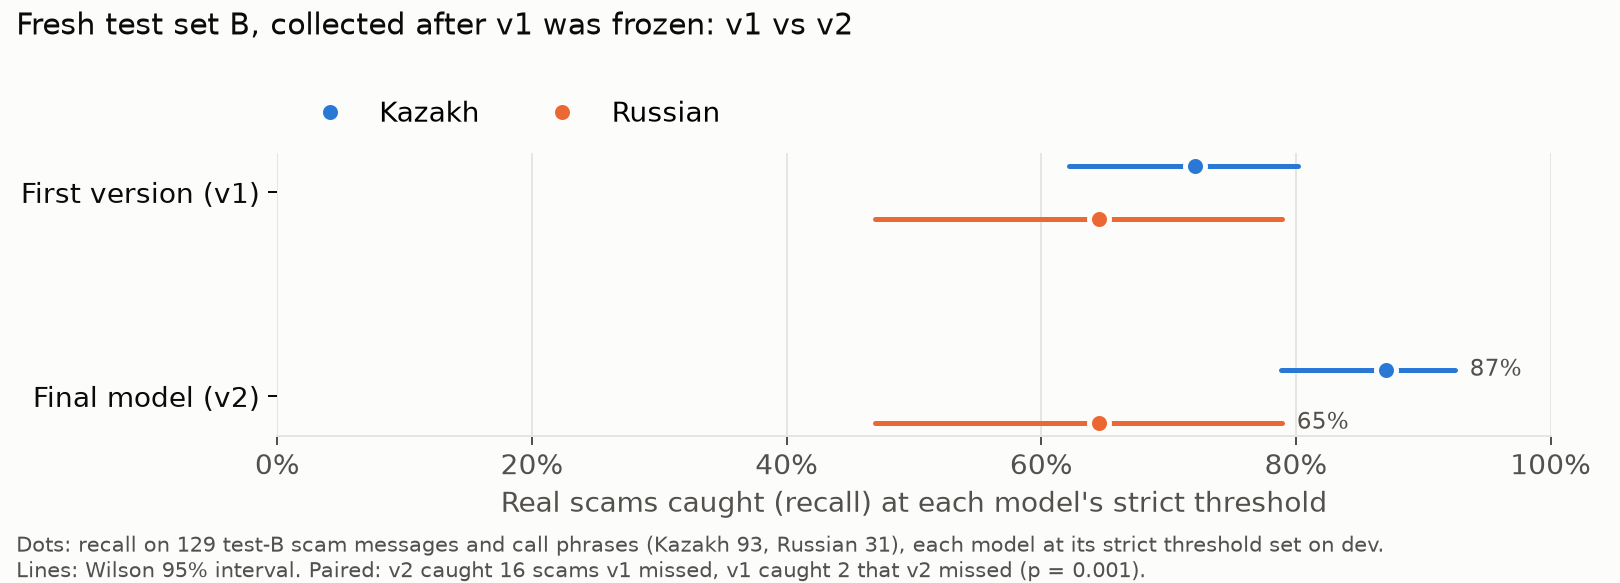

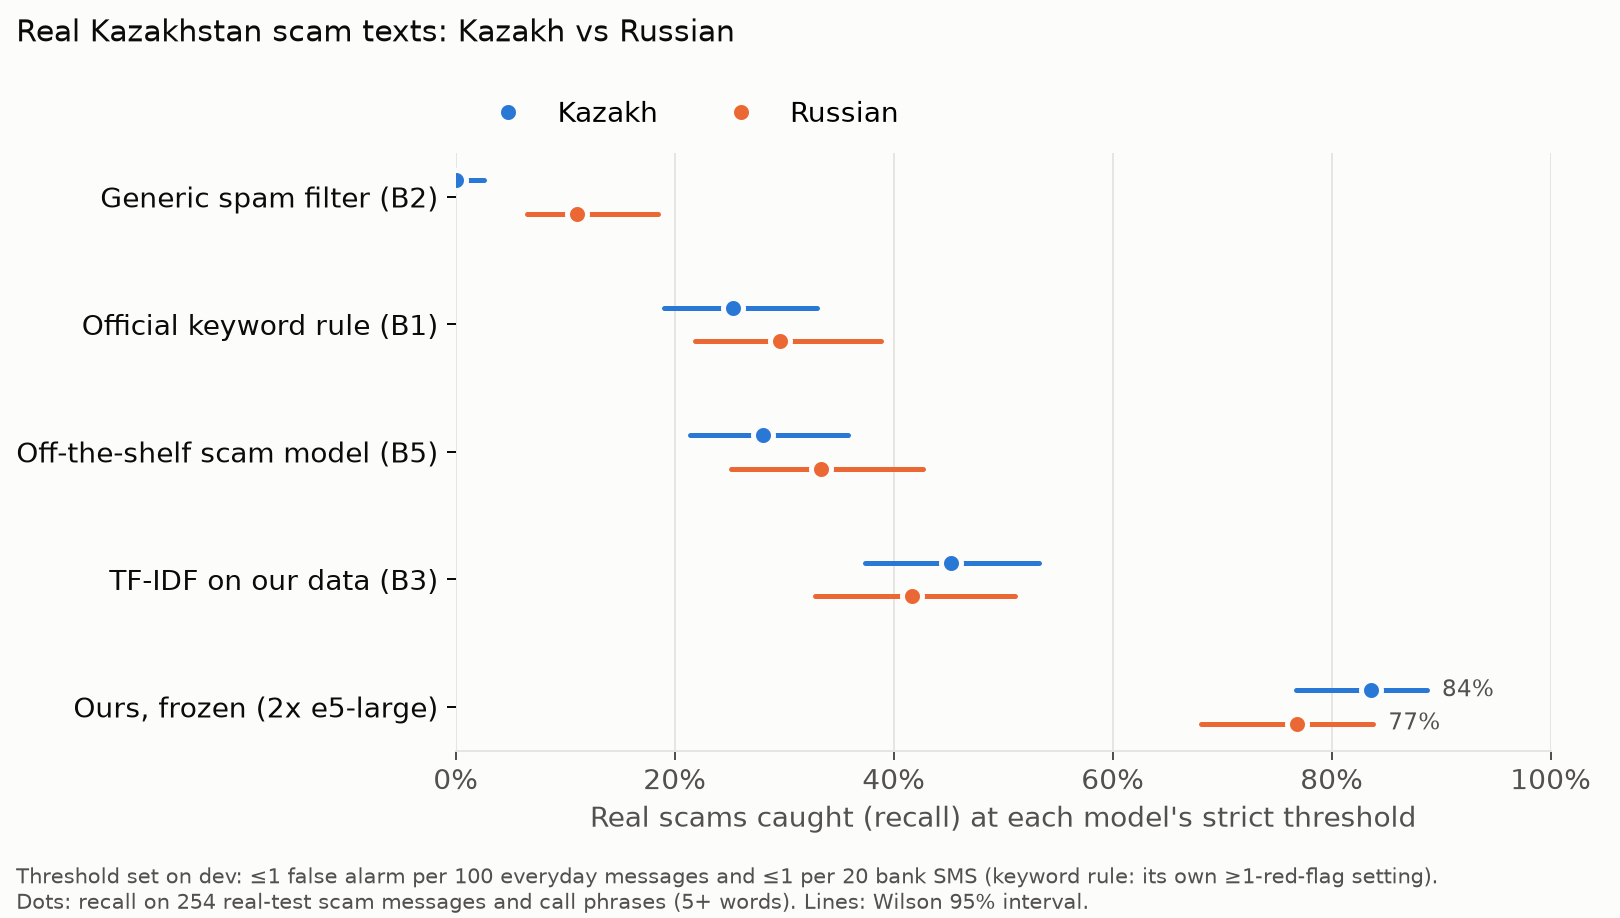

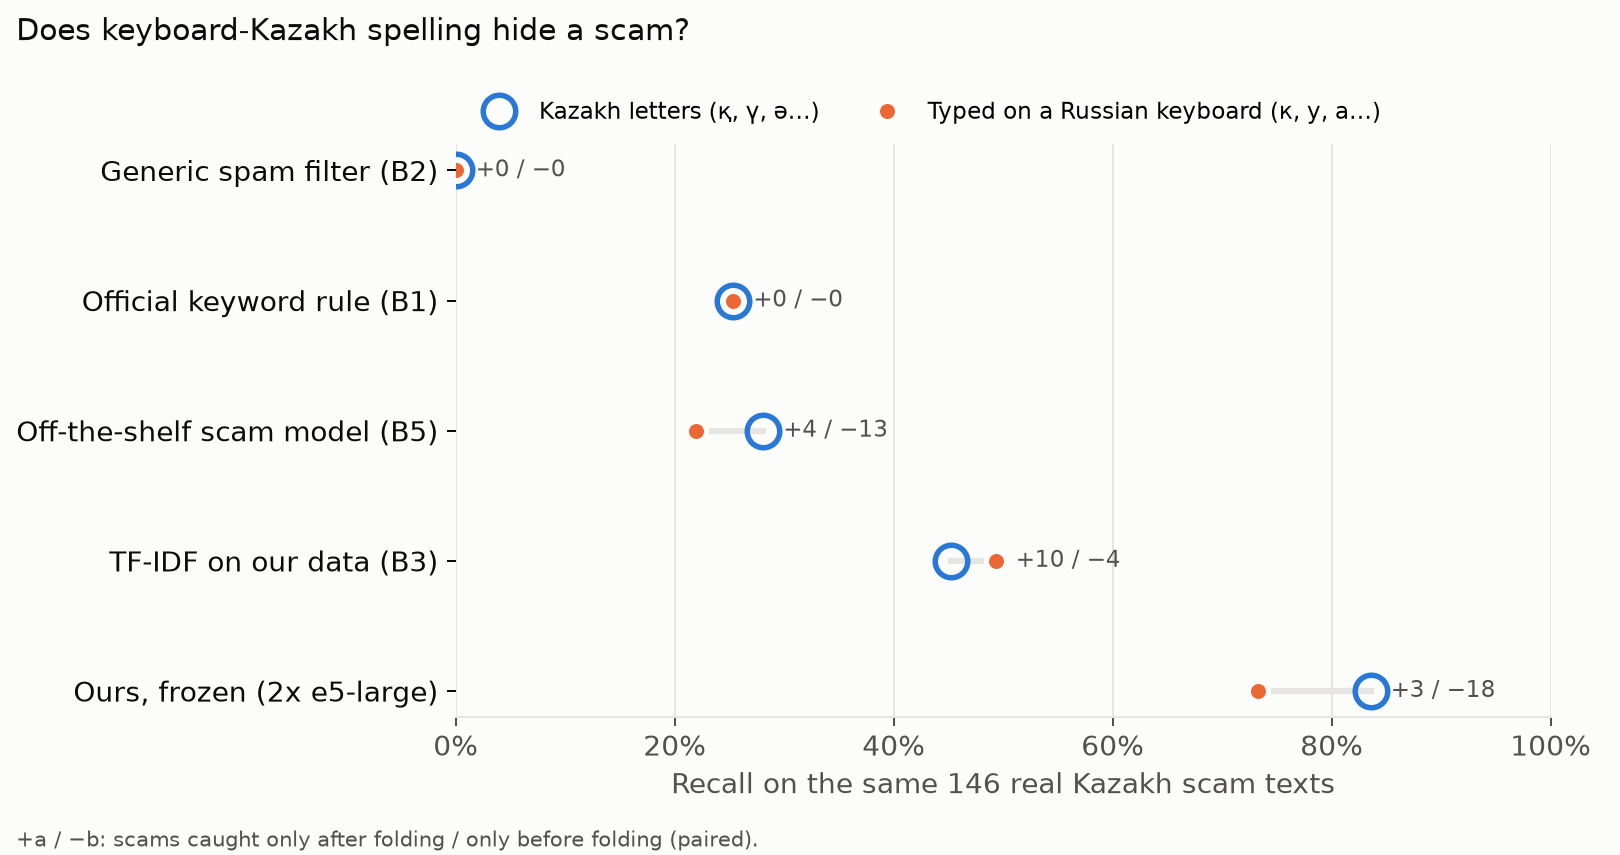

In [6]:
from IPython.display import Image, display
for f in ["reports/figures/fig_testB_v1_v2.png", "reports/figures/fig_recall_by_language.png", "reports/figures/fig_keyboard_kazakh.png"]:
    display(Image(f))

## 5. Where it fails (real-test examples)

In [7]:
p = pd.read_json(f"{FINAL_RUN}/{PREDS}", lines=True)
thr = final["thr_scam"]
print(f"Operating threshold (frozen, set on dev): {thr:.5f}. Scores below it are not flagged.")
# Recompute the headline numbers from raw predictions (no saved metrics used)
rt_ = p[p.set == "real_test"]; hs_ = rt_[(rt_.label == 1) & (rt_.headline == True)]
print("recomputed: recall", round((hs_.score >= thr).mean(), 4), "| kk", round((hs_[hs_.language == "kk"].score >= thr).mean(), 4), "| ru", round((hs_[hs_.language == "ru"].score >= thr).mean(), 4),
      "| chat FPR", round((p[p.set == "tg_test"].score >= thr).mean(), 4))
nt_ = rt_[(rt_.label == 0) & (rt_.unit == "notification")]
print(f"service SMS in this test set: {len(nt_)} (flagged {int((nt_.score >= thr).sum())}); too few to estimate a rate on test B")
from evaluate import mcnemar
v1p = pd.read_json("runs/ens_v6c_e5s2s3_testB/preds_final_testB.jsonl", lines=True)
m_ = p.merge(v1p, on=["id", "set"], suffixes=("", "_v1")); hs2 = m_[(m_.set == "real_test") & (m_.label == 1) & (m_.headline == True)]
print("paired on test-B scams, v2 vs v1 (McNemar):", mcnemar((hs2.score >= thr).astype(int), (hs2.score_v1 >= v1B["thr_scam"]).astype(int)))
rt = p[p.set == "real_test"]
print("Missed real scams (lowest scores):")
display(rt[(rt.label == 1) & rt.headline & (rt.score < thr)].sort_values("score")[["language", "unit", "score", "text"]].head(8))
print("Real legit texts flagged as scam:")
display(rt[(rt.label == 0) & (rt.score >= thr)].sort_values("score", ascending=False)[["language", "unit", "score", "text"]].head(8))
tg = p[p.set == "tg_test"]
print("Everyday chat flagged as scam:")
display(tg[tg.score >= thr].sort_values("score", ascending=False)[["language", "score", "text"]].head(5))

Operating threshold (frozen, set on dev): 0.99998. Scores below it are not flagged.
recomputed: recall 0.8217 | kk 0.871 | ru 0.6452 | chat FPR 0.0005
service SMS in this test set: 2 (flagged 0); too few to estimate a rate on test B
paired on test-B scams, v2 vs v1 (McNemar): {'n': 129, 'both': 90, 'only_first': 16, 'only_second': 2, 'neither': 21, 'mcnemar_p': 0.001312255859375}
Missed real scams (lowest scores):


,language,unit,score,text
3232,ru,message,0.692329,"смотрю на фото, вспоминаю тебя"
3170,kk,message,0.770459,Қорқыт ата атындағы Қызылорда университетіне қосымша ректор грантына немесе босаған білім гранттарына оқуға түсіріп ...
3072,kk,message,0.795753,"біз оқытушылар мен мұғалімдерден құралған бірлестікпіз, бізге семинар өткізе аласыз ба?"
3242,ru,call_phrase,0.921882,"Я [NAME] из поликлиники ""Шипагер"""
3132,kk,call_phrase,0.985065,"Қан тапсыруға жазып қояйық, орын шектеулі, 08:45–те бір ғана орын қалып тұр"
3241,ru,call_phrase,0.986348,Ваш заказ уже на складе
3074,kk,call_phrase,0.987001,әйтпесе сіз мүмкіндікті өткізіп аласыз
3210,ru,call_phrase,0.994199,по скидке давайте за 50 000 вам продадим


Real legit texts flagged as scam:


,language,unit,score,text
3175,kk,advice_text,0.999999,"Бұл ЖСН Жүйеде тіркелген,бар профиль үшін құпия сөзді енгізу керек"
3162,kk,advice_text,0.999996,Сіз операцияны өзіңіз жасап жатырсыз ба?
3161,kk,advice_text,0.999996,Операцияны өзіңіз жүргізіп жатырсыз ба?


Everyday chat flagged as scam:


,language,score,text
1085,ru,0.999996,"Вы уже отправили одну апелляцию. Наши специалисты постараются проверить её как можно скорее. Пожалуйста, подождите."


## 6. Try it
On Colab (Runtime > Change runtime type > T4 GPU) this downloads the two fine-tuned models from Hugging Face and opens the demo with a public link. Locally, run `python app.py runs/ens_v6c_e5s2s3_logit_z`.

In [8]:
import os
IN_COLAB = "google.colab" in sys.modules
cfg = json.load(open(f"{FINAL_RUN}/config.json"))
if IN_COLAB and HF_MODEL:
    from huggingface_hub import snapshot_download
    for m in cfg.get("members", [FINAL_RUN]):
        if not os.path.exists(f"{m}/best/model.safetensors"):
            snapshot_download(f"{HF_MODEL}-{os.path.basename(m).split('_')[-1]}", local_dir=f"{m}/best")
    os.environ["SAQBOL_SHARE"] = "1"
    sys.argv = ["app.py", FINAL_RUN]
    exec(open("app.py").read().replace('if __name__ == "__main__":', 'if True:'))
else:
    print("Demo launches on Colab. Locally: python app.py", FINAL_RUN)

Demo launches on Colab. Locally: python app.py runs/ens_v7_e5x4_logit_z
